# Part 2: MLE, EGARCH, VaR/ES, and Coverage

This notebook continues from Part 1. Make sure Part 1 has been run so that
`h`, `r`, `y`, `phi`, `sigma_eta`, `sigma`, and `kalman_filter` are all available.



In [4]:
# Imports — repeat here so Part 2 can also run standalone after Part 1
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
from arch import arch_model

# Known constant: E[log(chi^2_1)] — needed for the Harvey transform
mu_logchi = -1.2704


## Maximum Likelihood Estimation (MLE)




In [ ]:
# MLE Objective Function
# ─────────────────────────────────────────────────────────────────────────────

def kalman_filter_objfcn(params, y):
    """
    Objective function for MLE: returns the negative log-likelihood.

    Parameters
    ----------
    params : array-like  [phi, sigma_eta, sigma]
    y      : array (T,)  Harvey-transformed returns  log(r^2)

    Returns
    -------
    float : negative log-likelihood (must be a positive scalar)
    """
    phi_p, sigma_eta_p, sigma_p = params

    a   = np.log(sigma_p**2) + mu_logchi
    B   = 1.0
    Phi = phi_p
    H   = np.pi**2 / 2
    Q   = sigma_eta_p**2 
    a1  = 0.0
    P1  = sigma_eta_p**2  / (1-Phi**2)  

    return kalman_filter(y, a, B, Phi, H, Q, a1, P1, return_loglike=True)


### Task 3.2 — Optimise Parameters via MLE

Use `scipy.optimize.minimize` (method `'L-BFGS-B'`) to minimise the NLL.

- Initial guess: `[0.9, 0.3, 1.2]`
- Bounds: `[(0.001, 0.999), (1e-6, None), (1e-6, None)]`

Store the results using **these exact variable names** (required by the autograder):

| Variable | Description |
|----------|-------------|
| `phi_hat` | estimated φ |
| `sigma_eta_hat` | estimated σ_η |
| `sigma_hat` | estimated σ |


In [ ]:
# Task 3.2 — MLE Optimisation
# ─────────────────────────────────────────────────────────────────────────────

# Run the optimiser (scaffolding provided — do not change the bounds or method)
result = minimize(
    kalman_filter_objfcn,
    x0     = [0.9, 0.3, 1.2],                               # initial guess
    args   = (y,),                                           # Harvey-transformed data
    method = 'L-BFGS-B',
    bounds = [(0.001, 0.999), (1e-6, None), (1e-6, None)],  # parameter bounds
)

phi_hat       = result.x[0]
sigma_eta_hat = result.x[1]
sigma_hat     = result.x[2]

# Print comparison (will work once phi_hat etc. are assigned)
print(f"True:      phi={phi:.3f},  sigma_eta={sigma_eta:.3f},  sigma={sigma:.3f}")
print(f"Estimated: phi={phi_hat:.3f},  sigma_eta={sigma_eta_hat:.3f},  sigma={sigma_hat:.3f}")



True:      phi=0.950,  sigma_eta=0.200,  sigma=1.000
Estimated: phi=0.952,  sigma_eta=0.164,  sigma=1.107


### Filtered Log-Volatility with Estimated Parameters 



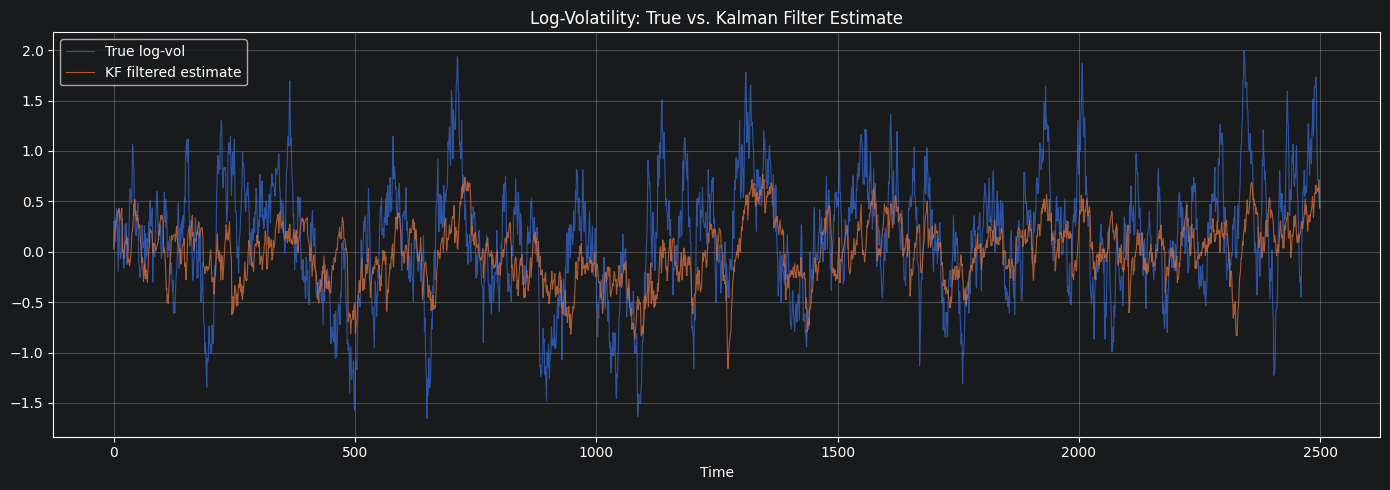

In [ ]:
# Filtered Log-Volatility with Estimated Parameters
# ─────────────────────────────────────────────────────────────────────────────

a_hat  = np.log(sigma_hat**2) + mu_logchi
P1_hat = sigma_eta_hat**2 / (1 - phi_hat**2)

a_post_hat, P_post_hat, _, _ = kalman_filter(
    y,               # Harvey-transformed returns from Part 1
    a_hat,           # constant offset (computed above)
    1.0,             # B
    phi_hat,             # Phi = phi_hat
    np.pi**2 / 2,             # H = pi^2 / 2
    sigma_eta_hat**2,             # Q = sigma_eta_hat^2
    0.0,             # a1
    P1_hat,          # prior variance (computed above)
)

# Plot: true log-vol vs. KF filtered estimate
plt.figure(figsize=(14, 5))
plt.plot(h, label='True log-vol', alpha=0.7, linewidth=0.8)
plt.plot(a_post_hat, label='KF filtered estimate', alpha=0.8, linewidth=0.8)
plt.title('Log-Volatility: True vs. Kalman Filter Estimate')
plt.xlabel('Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## EGARCH Model



In [ ]:
# Fit EGARCH(1,1)
# ─────────────────────────────────────────────────────────────────────────────

# Set up the EGARCH(1,1) model (do not change these arguments)
am = arch_model(r, vol='EGARCH', p=1, o=0, q=1)

res = am.fit(disp='off')

garch_vol = res.conditional_volatility

# Display model summary
print(res.summary())


                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -3839.28
Distribution:                  Normal   AIC:                           7686.57
Method:            Maximum Likelihood   BIC:                           7709.86
                                        No. Observations:                 2500
Date:                Sun, May 31 2026   Df Residuals:                     2499
Time:                        16:51:46   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0101  2.139e-02      0.471      0.637 

## Value-at-Risk (VaR) and Expected Shortfall (ES)

For a normal distribution with zero mean and time-varying volatility σ_t:

- **VaR_α(t)** = z_α × σ_t,   where z_α = `norm.ppf(alpha)` (negative for α < 0.5)
- **ES_α(t)** = −σ_t × φ(z_α) / α,   where φ(z) = `norm.pdf(z)`

Both VaR and ES are **negative** (left-tail convention). ES is **more negative** than VaR.



In [10]:
# Task 5.1 — VaR and ES Function
# ─────────────────────────────────────────────────────────────────────────────

def VaR_ES(stddev, alpha=0.05):
    """
    Compute Value-at-Risk and Expected Shortfall under a Gaussian assumption.

    Parameters
    ----------
    stddev : array-like  — conditional standard deviations (positive values)
    alpha  : float       — tail probability (default 0.05 = 5%)

    Returns
    -------
    VaR : array  — Value-at-Risk  (negative, left-tail convention)
    ES  : array  — Expected Shortfall  (more negative than VaR)
    """
    stddev = np.asarray(stddev)

    # alpha-quantile of the standard normal (negative for alpha < 0.5)
    z = norm.ppf(alpha)

    # TODO: VaR_alpha
    VaR = z * stddev

    # TODO: ES_alpha 
    ES = -stddev * norm.pdf(z) / alpha

    return VaR, ES


### Calculate VaR and ES for Both Models 




In [ ]:
# Compute VaR and ES
# ─────────────────────────────────────────────────────────────────────────────

alpha = 0.05

kf_vol = sigma_hat * np.exp(0.5 * a_post_hat)

VaR_KF, ES_KF = VaR_ES(kf_vol)


VaR_EGARCH, ES_EGARCH = VaR_ES(garch_vol)

print(f"KF     VaR (first 3): {VaR_KF[:3].round(4)}")
print(f"EGARCH VaR (first 3): {VaR_EGARCH[:3].round(4)}")


KF     VaR (first 3): [-1.8444 -1.9567 -2.0138]
EGARCH VaR (first 3): [-1.8856 -1.8494 -2.0445]


## Evaluate Model Performance with the Coverage Ratio

The **coverage ratio** is the fraction of time steps where the realised return
falls below the VaR.  If VaR is well-calibrated at level α, coverage ≈ α (e.g. 5%).



In [ ]:
# Coverage Ratio Function
# ─────────────────────────────────────────────────────────────────────────────

def coverage_ratio(returns, var_array):
    """
    Fraction of time steps where returns < VaR (left-tail exceedances).

    Parameters
    ----------
    returns   : array-like — return time series
    var_array : array-like — VaR time series (negative values)

    Returns
    -------
    float : fraction in [0,1]  — expected ≈ alpha for a calibrated VaR
    """
    returns   = np.asarray(returns)
    var_array = np.asarray(var_array)

    # TODO: return the fraction of times  r_t < VaR_t
    # Hint: use np.mean(...)
    return np.mean(returns < var_array)


### Calculate and Compare Coverage Ratios




In [ ]:
# Compute Coverage Ratios
# ─────────────────────────────────────────────────────────────────────────────

cov_kf    = coverage_ratio(r, VaR_KF)   # coverage_ratio for KF VaR
cov_garch = coverage_ratio(r, VaR_EGARCH)  # coverage_ratio for EGARCH VaR

print(f"KF     VaR coverage = {100 * cov_kf:.2f}%  (expected {alpha * 100:.0f}%)")
print(f"EGARCH VaR coverage = {100 * cov_garch:.2f}%  (expected {alpha * 100:.0f}%)")

if np.abs(cov_kf - alpha) < np.abs(cov_garch - alpha):
    print("Better Calibrated: KF VaR ")
else:
    print("Better Calibrated: EGARCH VaR")



KF     VaR coverage = 5.00%  (expected 5%)
EGARCH VaR coverage = 4.96%  (expected 5%)
Better Calibrated: KF VaR 


## Visualise Results



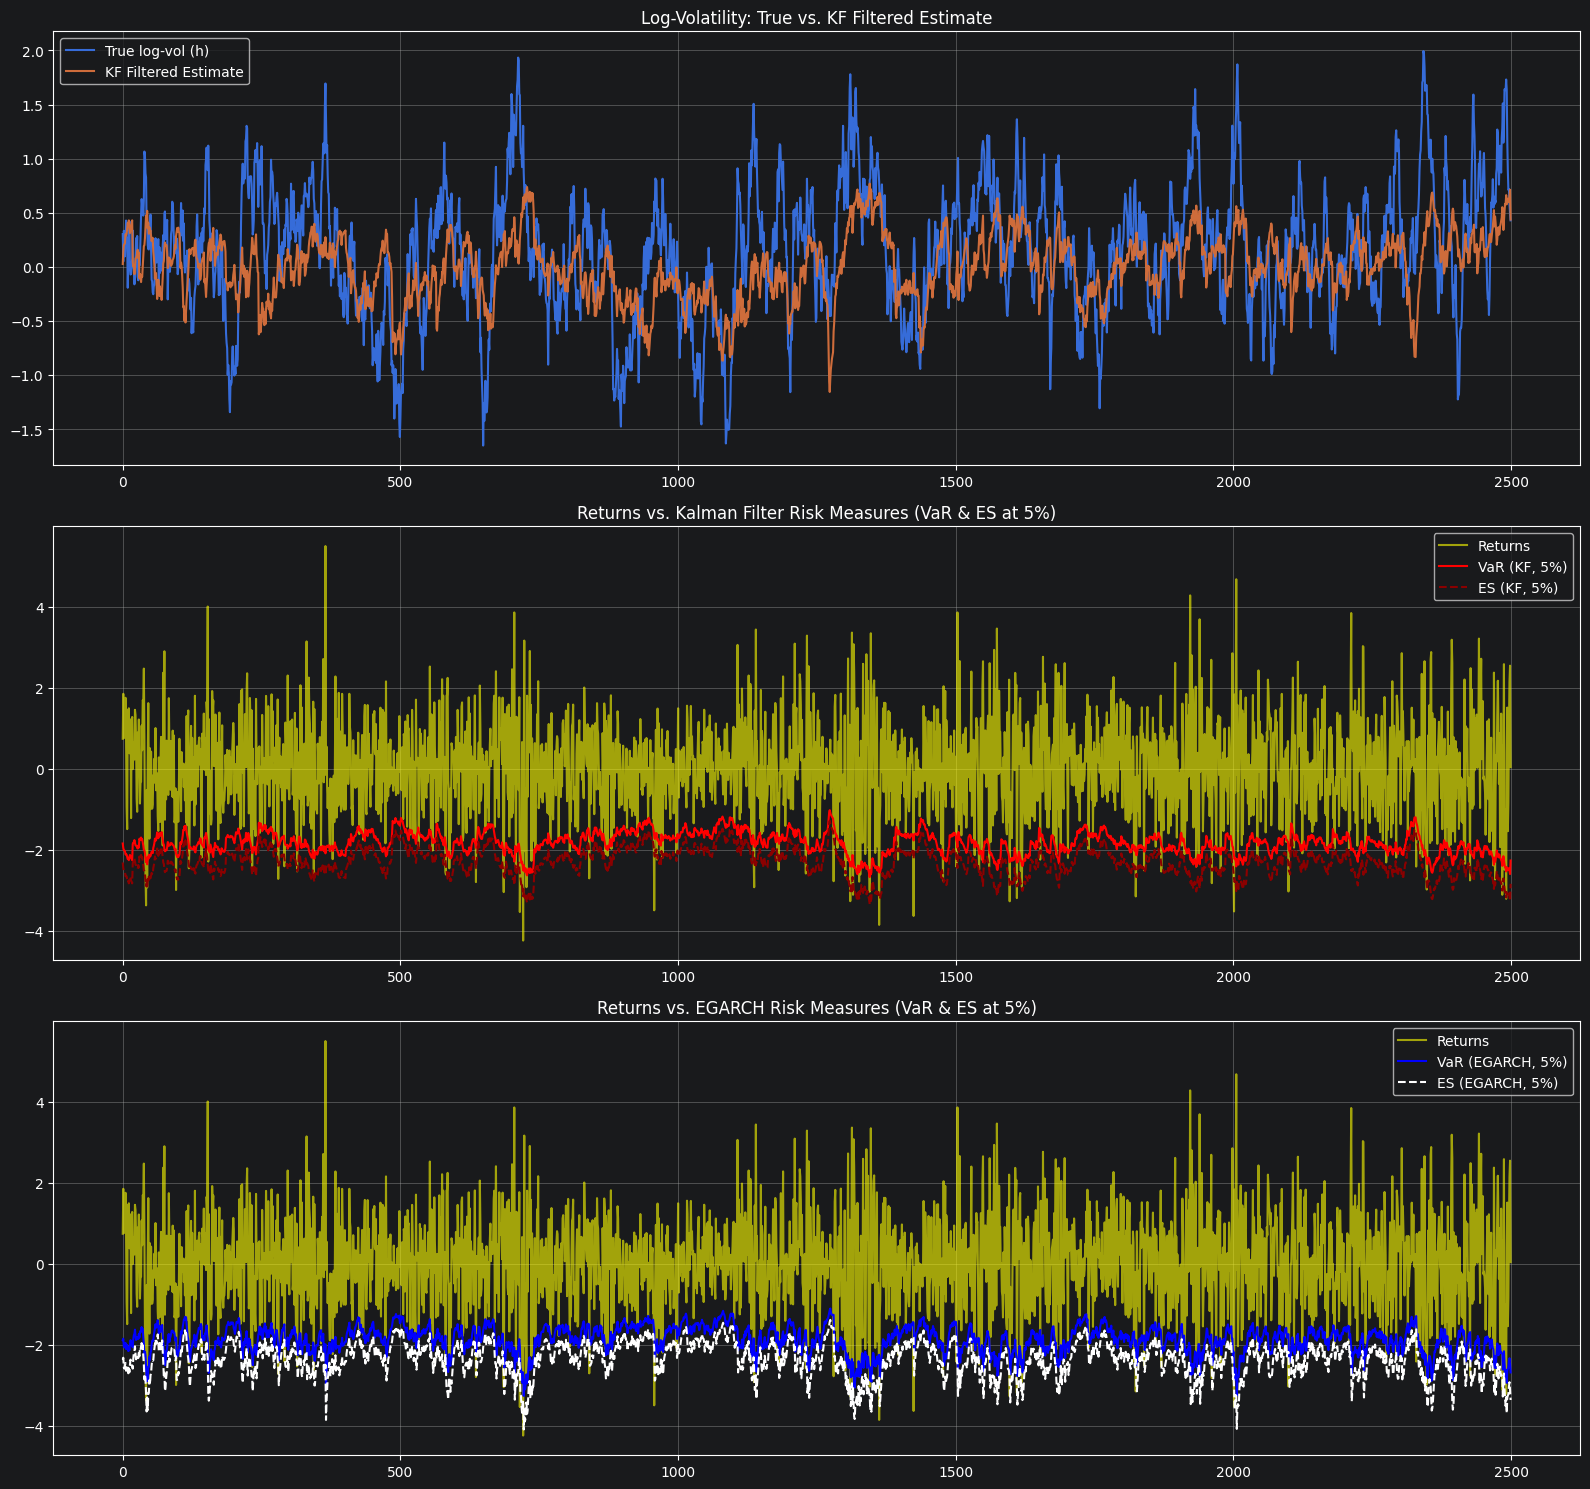

In [ ]:
# Comparative Visualisation
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(16, 15))

# --- Subplot 1: Log-volatility comparison ---
axes[0].plot(h, label='True log-vol (h)')
axes[0].plot(a_post_hat, label='KF Filtered Estimate')
axes[0].set_title('Log-Volatility: True vs. KF Filtered Estimate')
axes[0].legend()
axes[0].grid(True)

# --- Subplot 2: Returns vs. KF risk measures ---
axes[1].plot(r, label='Returns', color='yellow', alpha=0.6)
axes[1].plot(VaR_KF, label='VaR (KF, 5%)', color='red')
axes[1].plot(ES_KF, label='ES (KF, 5%)', color='darkred', linestyle='--')
axes[1].set_title('Returns vs. Kalman Filter Risk Measures (VaR & ES at 5%)')
axes[1].legend()
axes[1].grid(True)

# --- Subplot 3: Returns vs. EGARCH risk measures ---
axes[2].plot(r, label='Returns', color='yellow', alpha=0.6)
axes[2].plot(VaR_EGARCH, label='VaR (EGARCH, 5%)', color='blue')
axes[2].plot(ES_EGARCH, label='ES (EGARCH, 5%)', color='white', linestyle='--')
axes[2].set_title('Returns vs. EGARCH Risk Measures (VaR & ES at 5%)')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()
